In [ ]:
# Library pengolahan data
import numpy as np
import pandas as pd

# Library visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil dataset Breast Cancer
from sklearn.datasets import load_breast_cancer

# Library pembagian dataset dan normalisasi
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Library pipeline dan algoritma klasifikasi
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Library evaluasi model
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [ ]:
# Memuat dataset Breast Cancer Wisconsin
data = load_breast_cancer()

# Mengambil fitur dataset
X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Mengambil target atau label kelas
y = data.target

# Menampilkan ukuran dataset
print("Dataset Shape:", X.shape)

# Menampilkan lima data pertama
print("\nFirst 5 Samples:")
print(X.head())

# Menampilkan nama kelas
print("\nTarget Classes:")
print(data.target_names)

Dataset Shape: (569, 30)

First 5 Samples:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

In [ ]:
# Menampilkan informasi dataset
print("Dataset Information:")
X.info()

# Memeriksa missing values
print("\nMissing Values:")
print(X.isnull().sum().sum())

# Statistik deskriptif
print("\nStatistical Description:")
print(X.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

Class Distribution:
0    212
1    357
Name: count, dtype: int64


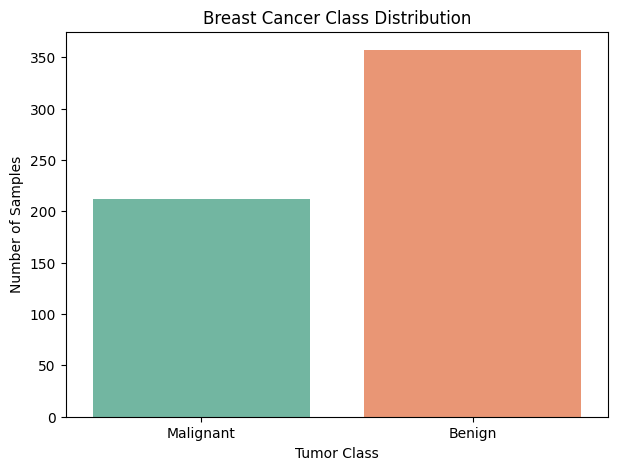

In [ ]:
# Menghitung jumlah setiap kelas
class_counts = pd.Series(y).value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

# Membuat visualisasi distribusi kelas
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"])

plt.show()

In [ ]:
# Membagi dataset menjadi 70% training dan 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Samples: 398
Testing Samples: 171

Training Features: (398, 30)
Testing Features: (171, 30)


In [ ]:
# Membuat model Logistic Regression
model_lr = make_pipeline(
    StandardScaler(),

    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

# Melatih model
model_lr.fit(X_train, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [ ]:
# Membuat model Random Forest Classifier
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Melatih model
model_rf.fit(X_train, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [ ]:
# Prediksi Logistic Regression
y_pred_lr = model_lr.predict(X_test)

# Prediksi Random Forest
y_pred_rf = model_rf.predict(X_test)

print("Actual Classes:")
print(y_test)

print("\nLogistic Regression Predictions:")
print(y_pred_lr)

print("\nRandom Forest Predictions:")
print(y_pred_rf)

Actual Classes:
[0 1 1 0 0 0 1 0 1 0 1 1 0 0 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1
 1 1 1 1 0 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1]

Logistic Regression Predictions:
[0 1 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1
 0 1 1 1 0 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1]

Random Forest Predictions:
[0 1 1 0 1 0 1 0 1 0 1 1 0 1 1 0 0 0 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 0
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 0 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 0 1 0
 

In [ ]:
# Menghitung akurasi Logistic Regression
accuracy_lr = accuracy_score(y_test, y_pred_lr)

# Menghitung akurasi Random Forest
accuracy_rf = accuracy_score(y_test, y_pred_rf)

# Membuat tabel perbandingan
comparison = pd.DataFrame({
    "Algorithm": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_rf
    ]
})

comparison["Accuracy (%)"] = (
    comparison["Accuracy"] * 100
)

print("Accuracy Comparison:")
print(comparison)

Accuracy Comparison:
             Algorithm  Accuracy  Accuracy (%)
0  Logistic Regression  0.988304     98.830409
1        Random Forest  0.935673     93.567251


In [ ]:
# Classification Report Logistic Regression
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=data.target_names
    )
)

# Classification Report Random Forest
print("\nRANDOM FOREST CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=data.target_names
    )
)

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



In [1]:
# Mengambil probabilitas prediksi Logistic Regression
y_probability_lr = model_lr.predict_proba(X_test)[:, 1]

# Mengambil probabilitas prediksi Random Forest
y_probability_rf = model_rf.predict_proba(X_test)[:, 1]

# Menghitung ROC-AUC
auc_lr = roc_auc_score(y_test, y_probability_lr)
auc_rf = roc_auc_score(y_test, y_probability_rf)

print("ROC-AUC Logistic Regression:", auc_lr)
print("ROC-AUC Random Forest:", auc_rf)

NameError: name 'model_lr' is not defined

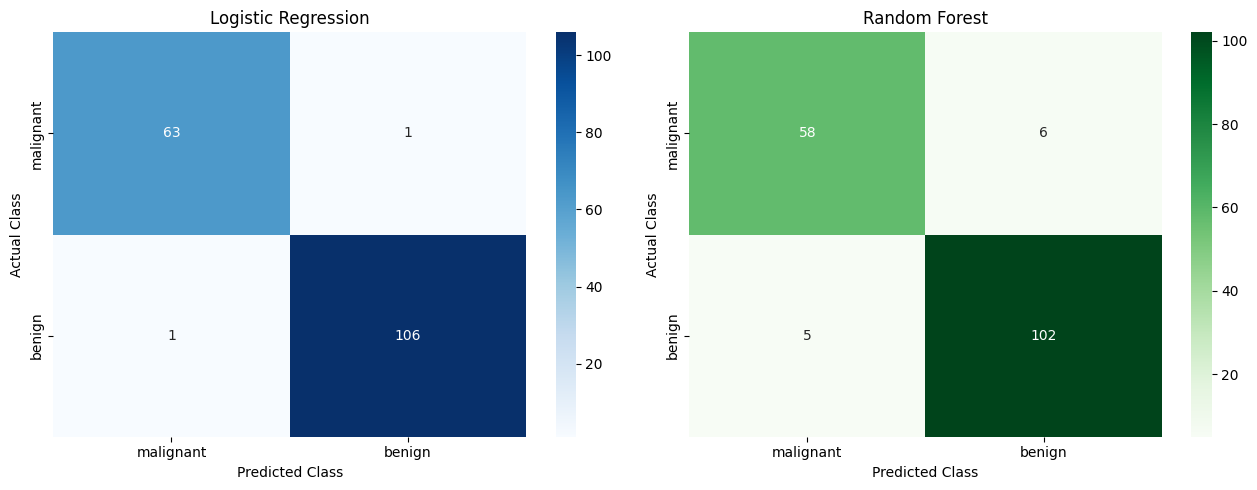

In [ ]:
# Menghitung Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Membuat visualisasi dua Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix Logistic Regression
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names,
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

# Confusion Matrix Random Forest
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=data.target_names,
    yticklabels=data.target_names,
    ax=axes[1]
)

axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

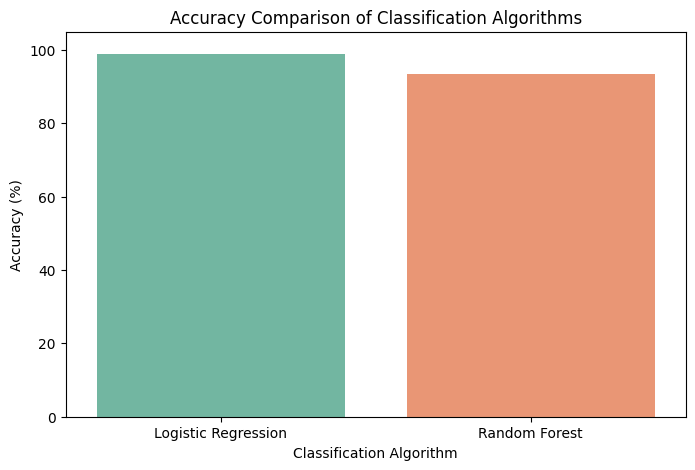

In [ ]:
# Membuat grafik perbandingan akurasi
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Algorithm",
    y="Accuracy (%)",
    hue="Algorithm",
    palette="Set2",
    legend=False
)

plt.title("Accuracy Comparison of Classification Algorithms")
plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)

plt.show()

In [ ]:
# Mengambil satu sampel dari data testing
sample = X_test.iloc[[0]]

# Menampilkan data sampel
print("Input Sample:")
print(sample)

# Prediksi Logistic Regression
prediction_lr = model_lr.predict(sample)[0]

# Prediksi Random Forest
prediction_rf = model_rf.predict(sample)[0]

# Menampilkan hasil prediksi
print("\nLogistic Regression Prediction:")
print(data.target_names[prediction_lr])

print("\nRandom Forest Prediction:")
print(data.target_names[prediction_rf])

Input Sample:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
14        13.73         22.61            93.6      578.3           0.1131   

    mean compactness  mean concavity  mean concave points  mean symmetry  \
14            0.2293          0.2128              0.08025         0.2069   

    mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
14                 0.07682  ...         15.03          32.01            108.8   

    worst area  worst smoothness  worst compactness  worst concavity  \
14       697.7            0.1651             0.7725           0.6943   

    worst concave points  worst symmetry  worst fractal dimension  
14                0.2208          0.3596                   0.1431  

[1 rows x 30 columns]

Logistic Regression Prediction:
malignant

Random Forest Prediction:
malignant


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Menghitung metrik evaluasi
hasil_evaluasi = pd.DataFrame({
    'Algoritma': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr, average='weighted'),
        precision_score(y_test, y_pred_rf, average='weighted')
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr, average='weighted'),
        recall_score(y_test, y_pred_rf, average='weighted')
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_lr, average='weighted'),
        f1_score(y_test, y_pred_rf, average='weighted')
    ]
})

print("Perbandingan Hasil Evaluasi Kedua Algoritma:")
display(hasil_evaluasi.round(4))

Perbandingan Hasil Evaluasi Kedua Algoritma:


,Algoritma,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9883,0.9883,0.9883,0.9883
1,Random Forest,0.9357,0.9355,0.9357,0.9356
